#### Convolution Neural Network
: 이미지 파일의 픽셀 하나하나를 보지 않고(불필요한 픽셀까지 해석하게 되는 문제 해결)<br>
정말 중요한 특징을 가진 픽셀을 구분하기 위한 필터를 씌워서 픽셀들의 묶

In [3]:
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset

In [ ]:
# 기본 구조
layer = nn.Conv2d(in_channels=1, out_channels=2, kernel_size=3)
# default : stride= 1, padding= 0

# out_channel= 2 는 서로다른 2개의 필터를 적용하여 2개의 특징을 도출, 
# 이후 nn.Sequential에서 다음 함수에 입력값 2개를 넣기 위함

layer(torch.randn(32, 1, 5, 5))       
layer(torch.randn(32, 1, 5, 5)).shape # (32,2,3,3)

torch.Size([32, 2, 3, 3])

## Linear와 Conv2d 비교

| 구분 | `nn.Linear()` | `nn.Conv2d()` |
| :--- | :--- | :--- |
| 명칭 | 완전연결층 (Fully Connected Layer) | 합성곱층 (Convolutional Layer) |
| 입력 속성 | `in_features` | `in_channels` |
| 출력 속성 | `out_features` | `out_channels` |
| 대표 입력 차원 | 2차원 `(N, F)` | 4차원 `(N, C, H, W)` |
| 연산 범위 | 전체 입력 Feature | 커널 내부의 국소 영역 |
| 공간 정보 | Flatten 적용 시 공간적 구조 소실 | 공간적 구조 유지 |
| 가중치 공유 | 공간 위치 기준 공유 없음 | 동일한 필터를 여러 공간 위치에서 반복 사용 |
| 주요 목적 | 특징 결합 및 재구성 | 공간적 특징 추출 |

### 차원별 의미

- `N` : Batch size (데이터 개수)
- `F` : Features (입력 특징 개수)
- `C` : Channels (채널 개수)
- `H` : Height (이미지 높이)
- `W` : Width (이미지 너비)

### 핵심 차이점

- **Linear** : 전체 입력 특징을 결합하여 새로운 특징을 생성
- **Conv2d** : 공간적 구조를 유지하면서 국소 영역의 특징을 추출
- **Weight Sharing** : Conv2d는 동일한 필터의 가중치를 여러 공간 위치에서 반복 사용하여 학습 파라미터의 수를 줄임

In [7]:
layer = nn.Conv2d(3,5,3)
# layer = nn.Conv2d(in_channels=3, out_channels=5, kernel_size=3)

layer(torch.randn(32,3,5,5))
layer(torch.randn(32,3,5,5)).shape  # (32,5,3,3)

print(layer.weight.shape)   # (특징(출력), 채널(입력), 행, 열)

torch.Size([5, 3, 3, 3])


In [11]:
conv1 = nn.Conv2d(1,8,6,stride=2)
x = torch.randn(32,1,28,28)
print(conv1(x).shape)

# H.out = {(H.in + 2*P - K) / S} + 1
# H.out(출력크기), H.in(입력크기), P(padding), K(kernel), S(stride)
conv2 = nn.Conv2d(8,16,3,padding=1)
print(conv2(conv1(x)).shape)

# maxpooling할 때 커널 사이즈와 stride는 일치하게 넣어야 함
maxpool = nn.MaxPool2d(kernel_size=2, stride=2)
print(maxpool(conv2(conv1(x))).shape)

torch.Size([32, 8, 12, 12])
torch.Size([32, 16, 12, 12])
torch.Size([32, 16, 6, 6])


In [ ]:
# MaxPool
maxpool = nn.MaxPool2d(2)   # 2 : kernel_size=2, stride=2
x = torch.randn(1,6,6)
print(x)
print(maxpool(x))

print(x.shape)
print(maxpool(x).shape)
print(maxpool(torch.randn(32,2,6,6)).shape)

tensor([[[ 0.0841, -1.0511, -1.4128, -0.7162, -1.2541, -1.7938],
         [ 0.4267,  0.5224, -0.6645,  0.6202, -0.7640,  1.1596],
         [ 0.9801, -1.0226, -1.3753,  0.9142,  1.0693, -0.2003],
         [-0.1083,  0.2739,  0.3641,  0.5172, -0.4891,  0.2501],
         [-0.5310, -0.6102, -0.2460,  1.3147, -1.6862, -0.6861],
         [-0.3704,  0.7797,  0.4487, -0.0731, -0.1593,  0.7284]]])
tensor([[[0.5224, 0.6202, 1.1596],
         [0.9801, 0.9142, 1.0693],
         [0.7797, 1.3147, 0.7284]]])
torch.Size([1, 6, 6])
torch.Size([1, 3, 3])
torch.Size([32, 2, 3, 3])


In [ ]:
# AvgPool
avgpool = nn.AvgPool2d(2)
x = torch.randn(1,6,6)
print(x)
print(avgpool(x))

tensor([[[-1.1064, -1.9253, -0.8094, -1.7861,  0.1418, -0.3363],
         [ 0.3028, -0.0400,  0.0899,  0.8518, -0.9588, -2.0722],
         [-0.8695, -0.6239,  0.6752, -0.4757, -0.2778, -0.8712],
         [-1.5935, -1.6466,  0.2656,  0.0721,  0.6641,  1.0354],
         [ 0.9567,  1.0737,  1.2292,  0.9205,  1.3613, -0.3698],
         [-0.2706, -2.1385,  0.0627,  0.6548,  1.3549, -0.7419]]])
tensor([[[-0.6922, -0.4134, -0.8064],
         [-1.1834,  0.1343,  0.1376],
         [-0.0947,  0.7168,  0.4012]]])


In [ ]:
# 클래스로 정의
class CNN(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__()
        self.conv1 = nn.Conv2d(1,8,6, stride=2)
        self.conv2 = nn.Conv2d(8,16,3, padding=1)
        self.maxpool = nn.MaxPool2d(2)
        self.fc = nn.Linear(16*6*6, 10)

    def forward(self, x):
        x = self.conv1(x)
        print('conv1:', x.shape)
        x = self.conv2(x)
        print('conv2:', x.shape)
        x = self.maxpool(x)
        print('maxpool:', x.shape)
        # 특징을 전부 다 잡고난 이후 Linear에 넣으려면 flatten 필요
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)

        return x    

x = torch.randn(32,1,28,28)
model = CNN()
print(model(x).shape)

conv1: torch.Size([32, 8, 12, 12])
conv2: torch.Size([32, 16, 12, 12])
maxpool: torch.Size([32, 16, 6, 6])
torch.Size([32, 10])


#### intel_image로 학습시킨 모델 생성

In [25]:
# function 파일 오류 수정 후 런타임을 재시작하지 않고 수정내용을 반영하는 방법
import importlib
import multiclass_functions
importlib.reload(multiclass_functions)

from multiclass_functions import *

In [26]:
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms, datasets
# datasets:  이미지 파일과 정답 레이블을 관리하고, 모델 학습에 사용할 수 있는 Dataset 객체를 생성하는 모듈
# transforms: 모델이 학습할 수 있도록 이미지의 크기, 자료형, 차원, 픽셀값 등을 변환하는 모듈입니다. 데이터 증강(Data Augmentation)에도 사용됩니다.
import matplotlib.pyplot as plt
import numpy as np
import os
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [ ]:
# 이미지 다운로드
import kagglehub
import shutil

# 저장 위치
data_dir = os.path.join(os.getcwd(), "data")

# 1. KaggleHub에서 데이터셋 가져오기
dataset_path = kagglehub.dataset_download(
    "puneet6060/intel-image-classification"
)

print("Kaggle 데이터 위치:", dataset_path)

# 2. data에 복사
os.makedirs(data_dir, exist_ok=True)

shutil.copytree(
    dataset_path,
    data_dir,
    dirs_exist_ok=True
)

print("저장 완료!")
print("최종 저장 위치:", data_dir)

In [27]:
# 이미지 전처리 및 Totensor() 설정
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

train_DS = datasets.ImageFolder(root='data/seg_train/seg_train', transform=transform)
test_DS = datasets.ImageFolder(root='data/seg_test/seg_test', transform=transform)

In [42]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 10
criterion = nn.CrossEntropyLoss()
new_model_train = True

model_type = 'CNN'
dataset = 'CIFAR10'

save_dir = 'results'
os.makedirs(save_dir, exist_ok=True)

save_model_path = f'{save_dir}/{model_type}_{dataset}.pt'

In [29]:
train_DL = DataLoader(train_DS, batch_size= BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size= BATCH_SIZE, shuffle=True)

In [39]:
# input : (32,3,64,64)
# conv1 : (32,8,30,30)
# conv2 : (32,16,30,30)
# maxpl : (32,16,15,15)
# fc    : (16*15*15,10)
class CNN(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__()
        self.conv1 = nn.Conv2d(3,8,6, stride=2)
        self.conv2 = nn.Conv2d(8,16,3, padding=1)
        self.maxpool = nn.MaxPool2d(2)
        self.fc = nn.Linear(16*15*15, 10)

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.maxpool(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)

        return x

In [40]:
model = globals()[model_type]().to(device)
print(model)
# model_type 은 하이퍼 파라미터 셀에서 model_type = 'MLP' 로 정의했기 때문에 변경희망시
# model_type = 'MLP_shallow' 로 변경하여 다시 셀 2 개를 실행하면 됨

x_batch, _ = next(iter(train_DL))
print(x_batch.shape)

CNN(
  (conv1): Conv2d(3, 8, kernel_size=(6, 6), stride=(2, 2))
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (maxpool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=3600, out_features=10, bias=True)
)
torch.Size([32, 3, 64, 64])


Epoch : 1, train loss : 0.489
--------------------
Epoch : 2, train loss : 0.451
--------------------
Epoch : 3, train loss : 0.425
--------------------
Epoch : 4, train loss : 0.403
--------------------
Epoch : 5, train loss : 0.379
--------------------
Epoch : 6, train loss : 0.360
--------------------
Epoch : 7, train loss : 0.341
--------------------
Epoch : 8, train loss : 0.329
--------------------
Epoch : 9, train loss : 0.304
--------------------
Epoch : 10, train loss : 0.295
--------------------


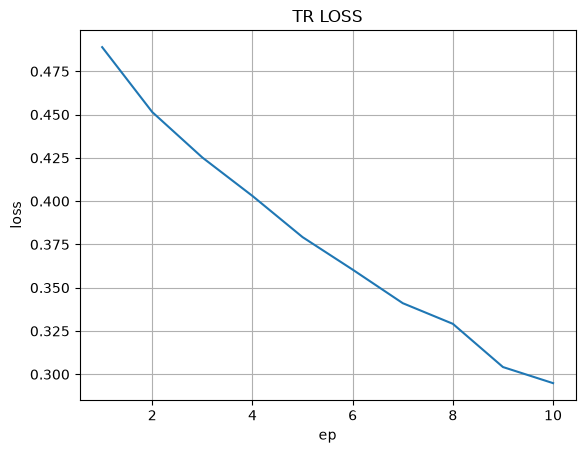

In [43]:
# if new_model_train == True:
if new_model_train:
  optimizer = optim.Adam(model.parameters(), lr=LR)
  loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

  torch.save(model, save_model_path)

  plt.figure()
  plt.plot(range(1, EPOCH+1), loss_history)
  plt.xlabel('ep')
  plt.ylabel('loss')
  plt.title('TR LOSS')
  plt.grid()

In [44]:
load_model = torch.load(save_model_path, map_location= device, weights_only=False)

In [45]:
Test(load_model, test_DL)
print(count_params(load_model))

Test accuracy : 2072 / 3000 (69.1 %)
38050


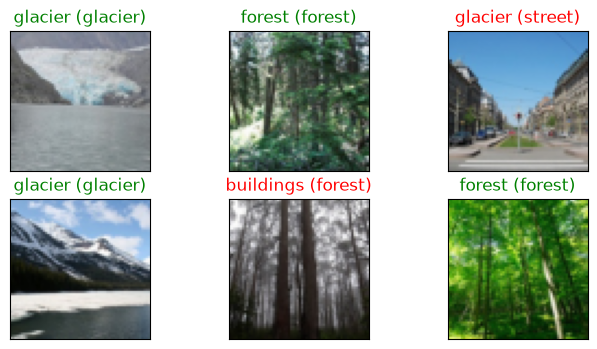

In [46]:
Test_plot(load_model, test_DL)

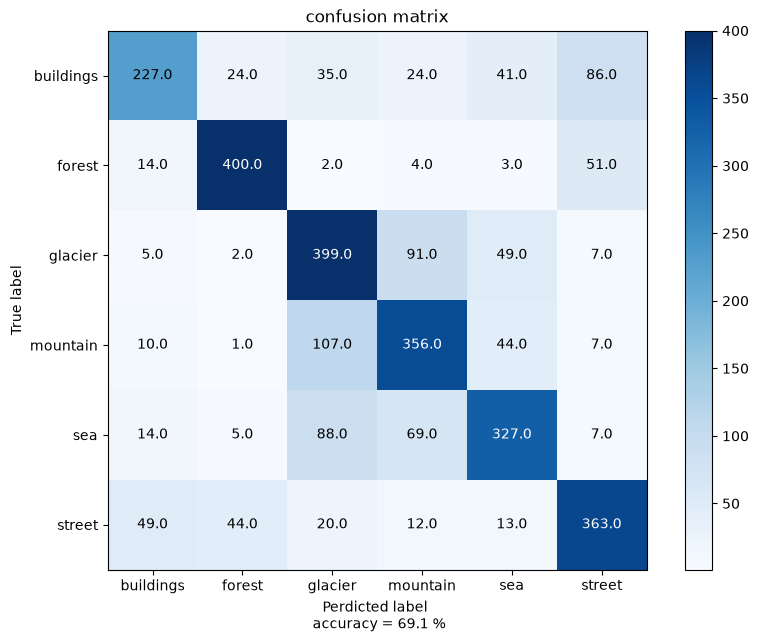

In [47]:
confusion = get_conf(load_model, test_DL)

plot_confusion_matrix(confusion, test_DS.classes)

In [2]:
# CUDA 사용확인

import torch

print('PyTorch Version :', torch.__version__)
print('CUDA Version    :', torch.version.cuda)
print('CUDA Available  :', torch.cuda.is_available())
print('GPU Count       :', torch.cuda.device_count())

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

print('DEVICE          :', DEVICE)

if torch.cuda.is_available():
    print('GPU Name        :', torch.cuda.get_device_name(0))
    print('cuDNN Version   :', torch.backends.cudnn.version())

PyTorch Version : 2.15.0+cu132
CUDA Version    : 13.2
CUDA Available  : True
GPU Count       : 1
DEVICE          : cuda
GPU Name        : NVIDIA GeForce RTX 4070 SUPER
cuDNN Version   : 92600


In [3]:
# CUDA 
x = torch.randn(3, 3, device=DEVICE)
y = torch.randn(3, 3, device=DEVICE)

z = x @ y

print(z)
print(z.device)

tensor([[-0.2234, -0.1440, -0.1934],
        [ 0.6815,  0.8543,  0.0164],
        [ 0.8554, -0.5579, -1.2841]], device='cuda:0')
cuda:0
